# Breast Cancer Wisconsin (Diagnostic) Dataset | Brustkrebs-Wisconsin (Diagnostischer) Datensatz

Ziel dieses Projekts ist es, mithilfe von Klassifikation
zwischen bösartigen (malignant) und gutartigen (benign) Tumoren zu unterscheiden.

Der Fokus liegt auf:
- sauberer Datenvorbereitung
- Modellvergleich
- verständlicher Evaluation und Interpretation

## 1. Import wichtiger Bibliotheken

In diesem Abschnitt werden die zentralen Bibliotheken für Datenanalyse, Visualisierung und Machine Learning importiert.  
Zusätzlich wird ein fester Zufallsstartwert gesetzt, um reproduzierbare Ergebnisse sicherzustellen.


In [2]:
import numpy as np # numerische Berechnungen und Reproduzierbarkeit
import pandas as pd # Einlesen und Analysieren der Daten
import matplotlib.pyplot as plt # Visualisierungen
import seaborn as sns # Visualisierungen

# Modellierung, Evaluation und Optimierung
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

np.random.seed(42)

## 2. Datenimport und erste Exploration
In diesem Abschnitt wird der Datensatz geladen und ein erster Überblick über Struktur und Kennzahlen gewonnen.

### 2.1 Datensatz laden

In [3]:
df = pd.read_csv("data/data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### 2.2 Überblick über Struktur und Kennzahlen

In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


**Beobachtung:**  

Der Datensatz enthält ausschließlich numerische Features (bis auf die Zielvariable).  
Die Wertebereiche unterscheiden sich stark, weshalb eine Feature-Skalierung für bestimmte Modelle notwendig ist.

- radius_mean ≈ 3–569
- area_mean ≈ 143–2501

## 3. Datenvorbereitung


### 3.1 Definition der Zielvariable

In [5]:
# Klassenverteilung zeigen
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

- `M` = malignant (bösartig)
- `B` = benign (gutartig)

Die Klassen sind leicht unausgeglichen, aber nicht stark verzerrt.
Aufgrund der Klassenverteilung betrachten wir zusätzlich Precision, Recall und ROC-AUC.

In [6]:
# Zielvariable in 0/1 umwandeln, damit sklearn arbeiten kann
df["diagnosis"] = df["diagnosis"].map({"M": 0, "B": 1})

# Trennung von Features (X) und Zielvariable (y)
X = df.drop(columns=["diagnosis", "id", "Unnamed: 32"], errors="ignore")
y = df["diagnosis"]

# Sicherstellen, dass nur numerische Features verwendet werden
X = X.select_dtypes(include=[np.number])


In [7]:
df['diagnosis'].value_counts()

diagnosis
1    357
0    212
Name: count, dtype: int64

### 3.2 Datenqualität und Bereinigung


In [8]:
# Prüfung auf fehlende Werte, um Datenqualität sicherzustellen
nan_cols = df.columns[df.isna().any()].tolist()
nan_cols

['Unnamed: 32']

Entfernen technischer Spalten und Features mit fehlenden Werten, um stabile Modelltrainings zu gewährleisten.

In [9]:
target_col = "diagnosis"

# Features und Zielvariable werden strikt getrennt, um Datenleckage zu vermeiden.
X = df.drop(columns=[target_col], errors="ignore").copy()
y = df[target_col].copy()

X = X.drop(columns=["id", "Unnamed: 32"], errors="ignore")

X = X.select_dtypes(include=[np.number])

X = X.dropna(axis=1)

X.shape, y.shape


((569, 30), (569,))

## 4. Explorative Datenanalyse (EDA)


### 4.1 Verteilungen und erste Auffälligkeiten der Features


Mit Histogrammen analysiere ich die Verteilung aller numerischen Features

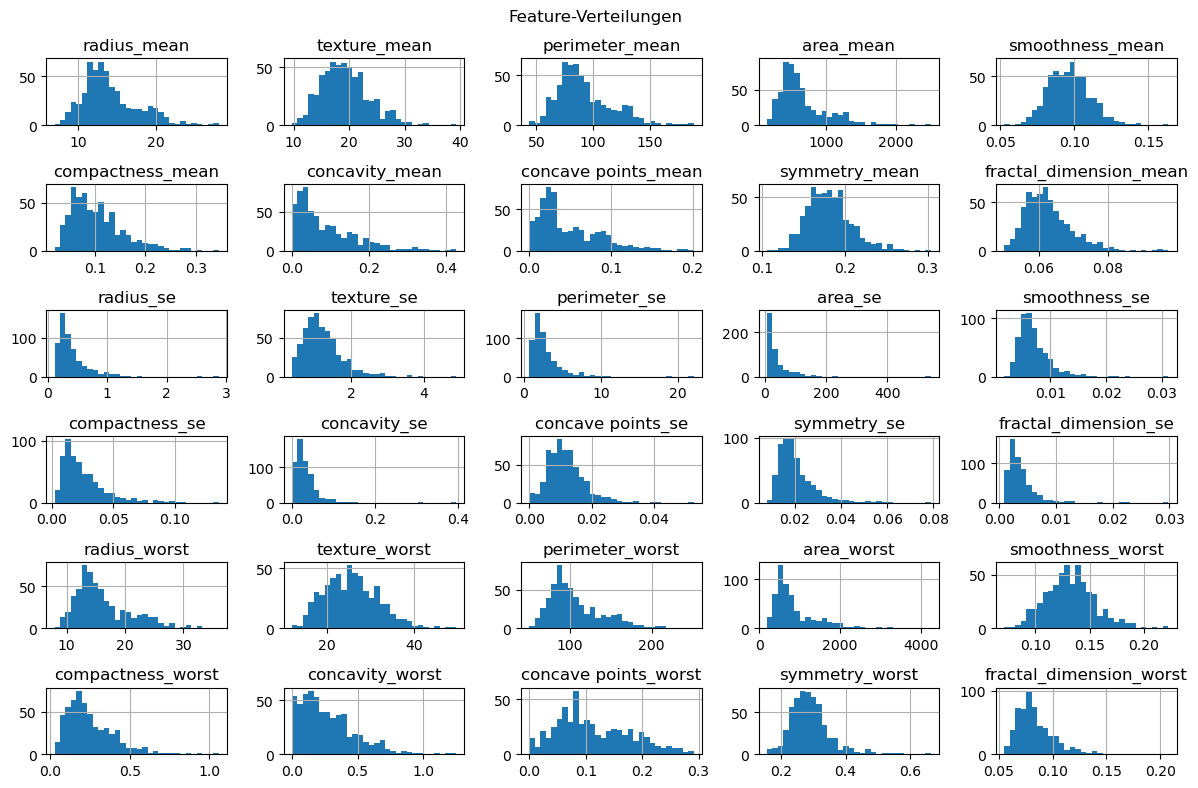

In [10]:
import matplotlib.pyplot as plt

X.hist(figsize=(12,8), bins=30)
plt.suptitle("Feature-Verteilungen")
# Das Layout wird automatisch optimiert, damit alle Diagramme gut lesbar sind
plt.tight_layout()
plt.show()

**Beobachtung:**

Die Histogramme zeigen, dass viele Features rechtsschief verteilt sind und potenzielle Ausreißer enthalten.  
Diese Beobachtung wird in der nächsten Analysephase genauer untersucht.


### 4.2 Ausreißeranalyse

Zur genaueren Untersuchung verwende ich Boxplots sowie die sogenannte IQR-Methode.

#### 4.2.1 Visuelle Identifikation potenzieller Ausreißer


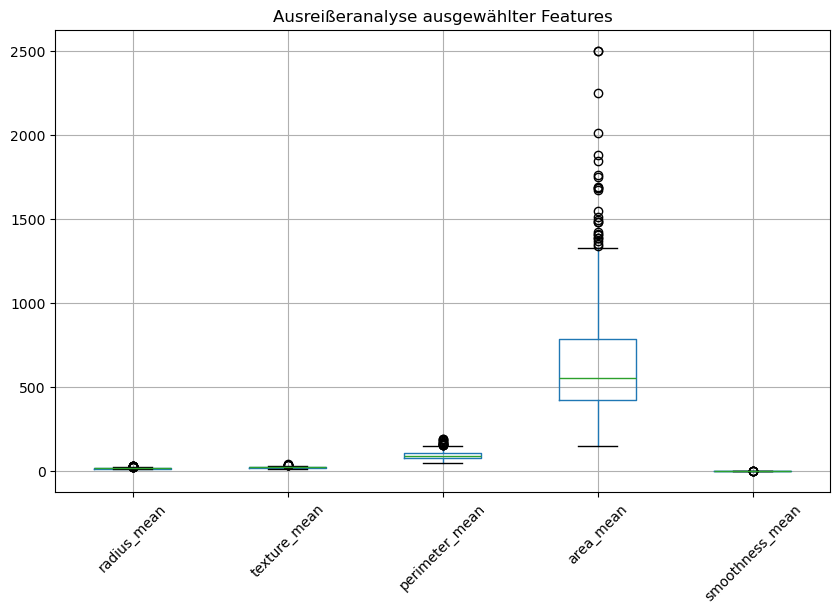

In [11]:
plt.figure(figsize=(10,6))
# die ersten 5 Spalten, welche in Boxplot umgewandelt werden
df[X.columns[:5]].boxplot()
plt.xticks(rotation=45)
plt.title("Ausreißeranalyse ausgewählter Features")
plt.show()

**Beobachtung:**

- Die Punkte außerhalb der Whiskers zeigen potenzielle Ausreißer
- Große Box → hohe Streuung, Kleine Box → kompakte Werte
- Man erkennt, dass einige Merkmale stark schiefe Verteilungen und Ausreißer aufweisen

#### 4.2.2 Behandlung von Ausreißern (IQR-Methode)

Ausreißer werden nicht blind entfernt, sondern mithilfe der IQR-Methode
identifiziert, um den Einfluss extremer Werte auf das Modell zu untersuchen.

In [12]:
# Funktion zur Identifikation potenzieller Ausreißer mittels IQR-Methode
def remove_outliers_iqr(df, columns):
    # Originaldaten bleiben unverändert
    df_clean = df.copy() 
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1 
        # Definition des akzeptierten Wertebereichs
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        # Werte innerhalb der Grenzen behalten, außerhalb kumulativ entfernen
        df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]
    return df_clean
df_outlier_clean = remove_outliers_iqr(df, X.columns)
df_outlier_clean.shape

(277, 33)

### 4.3 Korrelationsanalyse

Analyse der linearen Zusammenhänge zwischen den Features.

- Blau = negative Korrelation

- Rot = positive Korrelation

- Weiß = kaum Zusammenhang

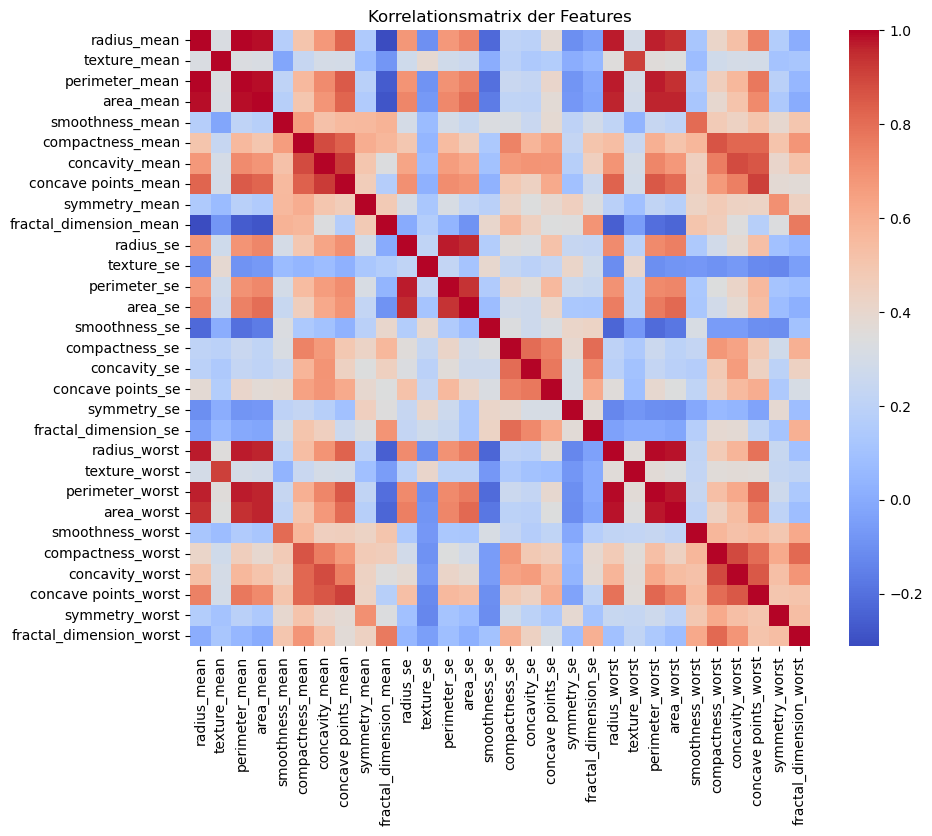

In [13]:
import seaborn as sns

plt.figure(figsize=(10,8))
# Berechnung der Korrelationen zur Analyse von Feature-Zusammenhängen
sns.heatmap(df[X.columns].corr(), cmap="coolwarm") 
plt.title("Korrelationsmatrix der Features")
plt.show()

**Beobachtung:**

Die Korrelationsmatrix zeigt stark zusammenhängende Merkmale, was auf redundante Informationen hinweist -> radius, perimeter, area = geometrische Merkmale mit ähnlichen Informationen

## 5. Feature-Analyse und Dimensionsreduktion

In diesem Abschnitt werden Zusammenhänge zwischen Features analysiert
und die hohe Dimensionalität der Daten mithilfe von PCA reduziert,
um die Struktur der Daten besser zu verstehen.


### 5.1 Dimensionsreduktion und Visualisierung (PCA)

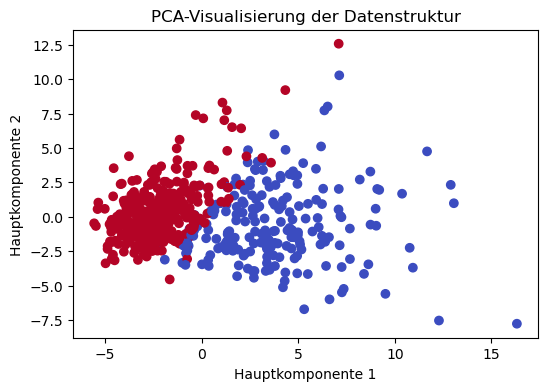

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separate Skalierung NUR für PCA (Analysezweck)
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X) 

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_pca)

plt.figure(figsize=(6,4))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap="coolwarm")
plt.xlabel("Hauptkomponente 1")
plt.ylabel("Hauptkomponente 2")
plt.title("PCA-Visualisierung der Datenstruktur")
plt.show()


Mit PCA lassen sich die Daten in zwei Dimensionen projizieren. Man erkennt, dass sich die Klassen gut (nicht perfekt, da keine Klassenlabels berücksichtigt werden) trennen lassen, was die Klassifizierbarkeit erklärt.

## 6. Modellierung


### 6.1 Train-Test-Split und Feature-Skalierung

Die Daten werden in Trainings- und Testdaten geteilt. Anschließend werden Features skaliert (wichtig für Logistic Regression).

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Aufteilung in Trainings- und Testdaten mit Stratifizierung der Zielvariable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature-Skalierung basierend ausschließlich auf den Trainingsdaten (Vermeidung von Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 6.2 Baseline-Modell: Logistische Regression




Ich verwende logistische Regression als Baseline, da sie ein robustes und gut interpretierbares Klassifikationsmodell ist.

Das Modell wird ausschließlich mit den skalierten Trainingsdaten trainiert, um Data Leakage zu vermeiden. Anschließend werden Vorhersagen für die Testdaten erzeugt, die für die spätere Modellbewertung verwendet werden.

In [16]:
from sklearn.linear_model import LogisticRegression

# Die maximale Iterationszahl wurde erhöht, um eine stabile Konvergenz des Optimierungsverfahrens sicherzustellen.
log_reg = LogisticRegression(max_iter=1000)
# Das Modell wird ausschließlich mit den skalierten Trainingsdaten trainiert, um Data Leakage zu vermeiden
log_reg.fit(X_train_scaled, y_train)

# Anschließend wird das Modell auf den Testdaten evaluiert, um die Generalisierungsfähigkeit zu prüfen
y_pred = log_reg.predict(X_test_scaled)

print("OK, Modell trainiert")



OK, Modell trainiert


## 7. Modellbewertung und Fehleranalyse


### 7.1 Evaluationsmetriken

Bewertung mit Accuracy sowie Precision/Recall/F1.

In [17]:
from sklearn.metrics import accuracy_score, classification_report

# korrekte Vorhersagen/alle Vorhersagen
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["malignant (M)", "benign (B)"]))

Accuracy: 0.9824561403508771
               precision    recall  f1-score   support

malignant (M)       0.98      0.98      0.98        42
   benign (B)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



**Beobachtung:**

Das Modell erreicht eine Accuracy von 98,25 %, was auf eine sehr hohe Gesamtleistung hinweist.  
Für eine fundierte Bewertung werden zusätzlich Precision, Recall und F1-Score betrachtet.

Besonders relevant ist der Recall der malignen Klasse (0,98), da ein Übersehen bösartiger Tumore schwerwiegende medizinische Folgen hätte. Der hohe Recall zeigt, dass das Modell die meisten malignen Fälle korrekt erkennt.

Die Precision-Werte sind ebenfalls sehr hoch, was bedeutet, dass Fehlalarme selten auftreten. Der F1-Score bestätigt die ausgewogene Modellleistung.

Da sich Macro Average und Weighted Average kaum unterscheiden, ist das Modell nicht zugunsten einer bestimmten Klasse verzerrt.

### 7.2 Fehleranalyse: Confusion Matrix

Die Confusion Matrix zeigt die Anzahl korrekt und falsch klassifizierter Fälle.
Im medizinischen Kontext sind insbesondere False Negatives kritisch.

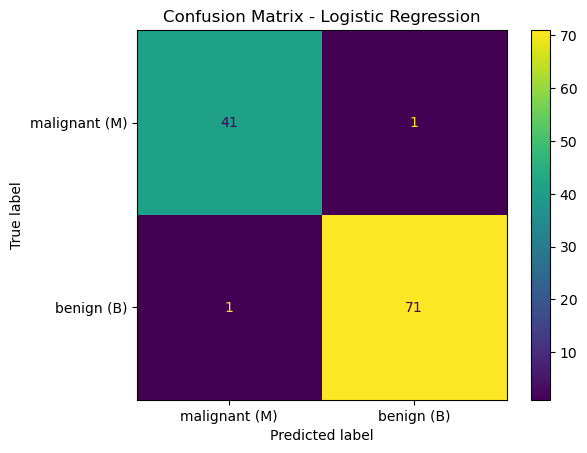

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["malignant (M)", "benign (B)"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

False Positives sind weniger kritisch, da sie lediglich zu weiteren Untersuchungen führen würden. Insgesamt zeigt die Confusion Matrix eine sehr zuverlässige Klassifikationsleistung des Modells.

### 7.3 ROC-Kurve und AUC-Wert

Zeigt die Trennschärfe des Modells unabhängig vom Schwellenwert.


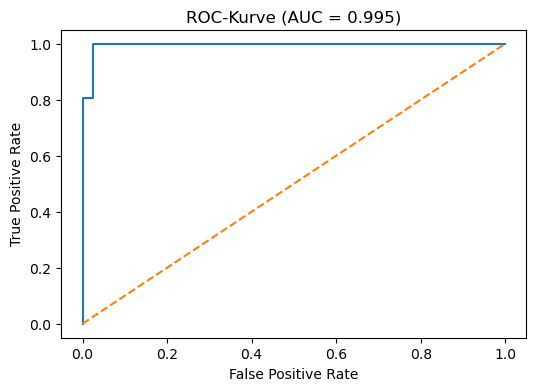

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC benötigt Wahrscheinlichkeiten
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_proba)
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC-Kurve (AUC = {auc:.3f})")
plt.show()


Die ROC-Kurve zeigt eine sehr gute Trennfähigkeit des Modells. AUC nahe 1.0

## 8. Modellverbesserung und Vergleich


### 8.1 Vergleichsmodell: Random Forest

Random Forest(Entscheidungsbäume) kann nicht-lineare Zusammenhänge modellieren und dient als Leistungs-Vergleich zur Baseline.


In [20]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=["malignant (M)", "benign (B)"]))

Random Forest Accuracy: 0.956140350877193
               precision    recall  f1-score   support

malignant (M)       0.95      0.93      0.94        42
   benign (B)       0.96      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



Obwohl der Random Forest ein komplexeres Modell ist, liefert er hier keinen Performance-Gewinn. Die logistische Regression passt besser zur Datenstruktur und erkennt bösartige Tumore zuverlässiger.

Das einfachere Modell(log.Reg.) ist hier besser geeignet, weil...

- Datensatz ist gut linear trennbar (s.PCA & Korrelationen),
- Random Forest profitiert eher von mehr Daten
- Kein Hyperparameter-Tuning für fairen Vergleich

### 8.2 Feature Importance und Modellinterpretation



Random Forest kann die relative Wichtigkeit der Features berechnen

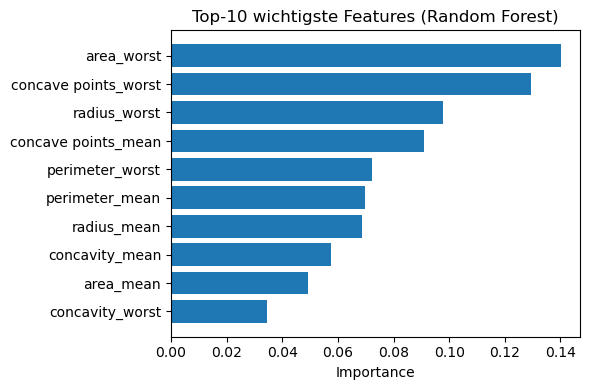

In [21]:
importances = rf.feature_importances_
# Ich wähle die zehn wichtigsten Features anhand ihrer Importance(aufsteigend)
indices = np.argsort(importances)[-10:]

plt.figure(figsize=(6,4))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), X.columns[indices])
plt.xlabel("Importance")
plt.title("Top-10 wichtigste Features (Random Forest)")
plt.tight_layout()
plt.show()

**Beobachtung:**

Besonders die worst-Features sind dominant, was darauf hindeutet, dass extreme Ausprägungen eines Tumors relevanter sind als Durchschnittswerte. 
 
Insbesondere Größen- und Formmerkmale wie Radius, Fläche und konkave Punkte weisen eine hohe Relevanz auf, was medizinisch plausibel ist.

Die Analyse dient als Plausibilitätsprüfung. Aufgrund von Korrelationen zwischen Features und modellbedingten Verzerrungen sind die Importance-Werte nicht kausal zu interpretieren.


### 8.3 Hyperparameter-Optimierung (Logistische Regression)
Zur Verbesserung der Modellleistung werden verschiedene
Hyperparameter der logistischen Regression getestet.
Hierbei wird insbesondere der Regularisierungsparameter C optimiert.


Zur Optimierung der logistischen Regression wurde eine Grid Search mit Cross-Validation durchgeführt.  
Mithilfe einer Pipeline wird sichergestellt, dass die Feature-Skalierung ausschließlich auf Trainingsdaten erfolgt und somit Data Leakage vermieden wird.

Als Optimierungskriterium wurde der F1-Score gewählt, da er Precision und Recall kombiniert und für medizinische Klassifikationsprobleme besonders geeignet ist. Die Grid Search ermittelt den Regularisierungsparameter, der die beste durchschnittliche Modellleistung erzielt.


In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10]
}

grid = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="f1"
)

grid.fit(X_train, y_train)

print("Bestes C:", grid.best_params_)
print("Beste CV-F1:", grid.best_score_)

Bestes C: {'model__C': 0.1}
Beste CV-F1: 0.984524686809138


**Beobachtung:**

Das optimale Regularisierungsniveau liegt bei C = 0.1, was auf ein gutes Gleichgewicht zwischen Modellkomplexität und Generalisierung hindeutet.

Der hohe Cross-Validation-F1-Score zeigt eine sehr stabile Modellleistung über verschiedene Datenaufteilungen hinweg

Testcheck: Zur finalen Bewertung verwende ich Accuracy und F1-Score

In [23]:
from sklearn.metrics import accuracy_score, f1_score

# Das beste Modell enthält die komplette Pipeline inklusive Skalierung
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)

print("Test Accuracy (best):", accuracy_score(y_test, y_pred_best))
print("Best Model Test F1:", f1_score(y_test, y_pred_best))

Test Accuracy (best): 0.9736842105263158
Best Model Test F1: 0.9793103448275862


Die Test-Accuracy zeigt eine sehr hohe Gesamtgenauigkeit auf bisher ungesehenen Daten.
Der hohe F1-Score zeigt, dass das Modell sowohl zuverlässig als auch sensitiv ist

## 9. Robustheit und Validierung


### 9.1 Cross-Validation

Zur Überprüfung der Robustheit wurde eine 5-fache Cross-Validation durchgeführt. Dabei wird das Modell fünfmal auf unterschiedlichen Trainings- und Validierungssets getestet. Absicherung, dass das Ergebnis nicht vom zufälligen Split abhängt.


In [24]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline verhindert Data Leakage innerhalb der Cross-Validation:
# Der StandardScaler wird in jedem Fold ausschließlich auf den
# jeweiligen Trainingsdaten angepasst.
cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV Accuracy:", scores)
print("Mean CV Accuracy:", scores.mean())

CV Accuracy: [0.96703297 0.97802198 0.96703297 1.         0.98901099]
Mean CV Accuracy: 0.9802197802197803


Die Accuracy-Werte liegen konstant zwischen 96 % und 100 %, mit einer mittleren Accuracy von etwa 98 %. Das zeigt, dass das Modell stabil ist und gut generalisiert.

## 10. Fazit

Zusammenfassend zeigt dieses Projekt, dass durch eine saubere Datenvorbereitung, fundierte explorative Analyse, eine geeignete Modellwahl und eine umfassende Evaluation sehr zuverlässige Ergebnisse erzielt werden können. Besonders die logistische Regression erweist sich hier als eine ausgezeichnete Wahl, da sie eine hohe Leistung mit guter Interpretierbarkeit verbindet, was im medizinischen Kontext von zentraler Bedeutung ist.